# MCMC analysis of cosmological FRB constraints using the Pade Approximants

**Note**: This notebook uses the updated formalism developed for Zhuge+ (2025) [[here](https://arxiv.org/abs/2508.05161)], and a Gaussian PDF for comparison.

**Default Runs**

- $N_s=15000$ samples (minus `burn-in`)
- `z_min=0.25`
- Cosmological priors: $H_0 \ \epsilon \ [40, 100]$ km/s/Mpc, $\Omega_m \ \epsilon \ [0.0, 1.0]$, $w \ \epsilon \ [-2.0, 0.0]$

## Run properties and loading modules

In [31]:
### If the MCMC functions need to be imported from a file, this should be OFF
## Depends on how the OS handles multiprossecing
SAVE_DATA = True
SAVE_FIG = True
LOAD_DATA = True

In [2]:
import sys
sys.path.append('../Python_scripts')
DATA_PATH = './interpolation/095_C0mean.npz'

### Import packages
from config import *
from support import *
from cosmo_support import *
from mcmc_support import *

In [3]:
## Plotting
plt.rcParams['font.family'] ='Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

## Collect Data

In [4]:
import pandas as pd

In [5]:
frb_data_all=pd.read_csv('../Data/FRB_new_highz_event.csv')

In [6]:
z_cut=0.25

## Cutting the data
frb_data_cut = frb_data_all[frb_data_all['FRB'] != 'FRB 20190520B'] 
frb_data_cut = frb_data_cut[frb_data_cut['FRB'] != 'FRB 20220831A']
frb_data_cut = frb_data_cut[frb_data_cut['z'] >= z_cut]

frb_data_cut_lowZ = frb_data_cut[frb_data_cut['FRB'] != 'FRB 20240304B']

print(f"Original data had {len(frb_data_all)}, while the cut data have {len(frb_data_cut)} FRBs.")
print(f"Original data had {len(frb_data_all)}, while the cut lowZ data have {len(frb_data_cut_lowZ)} FRBs.")

Original data had 118, while the cut data have 45 FRBs.
Original data had 118, while the cut lowZ data have 44 FRBs.


In [7]:
frb_data_cut.head()

,FRB,z,gl,gb,DM,"DM_MW, ISM(NE2001)","DM_MW, ISM(YMW16)",DM_ext(ne2001),DM_ext(ymw16),Ref.
3,FRB 20220610A,1.01500,8.839200,-70.185700,1458.10,30.96,13.58,1397.142120,1414.521089,ASKAP2
4,FRB 20220717A,0.36295,19.835158,-17.632032,637.34,118.33,83.22,489.008396,524.116215,https://arxiv.org/pdf/2407.02173
6,FRB 20230521B,1.35400,115.650000,9.970000,1342.90,133.40,197.80,1179.501944,1115.100378,https://arxiv.org/pdf/2409.16952
7,FRB 20230814A,0.55300,112.560000,13.200000,696.40,104.76,137.79,561.640318,528.611960,https://arxiv.org/pdf/2409.16952
8,FRB 20231220A,0.33550,143.290000,31.690000,491.20,50.27,45.17,410.934486,416.027064,https://arxiv.org/pdf/2409.16952


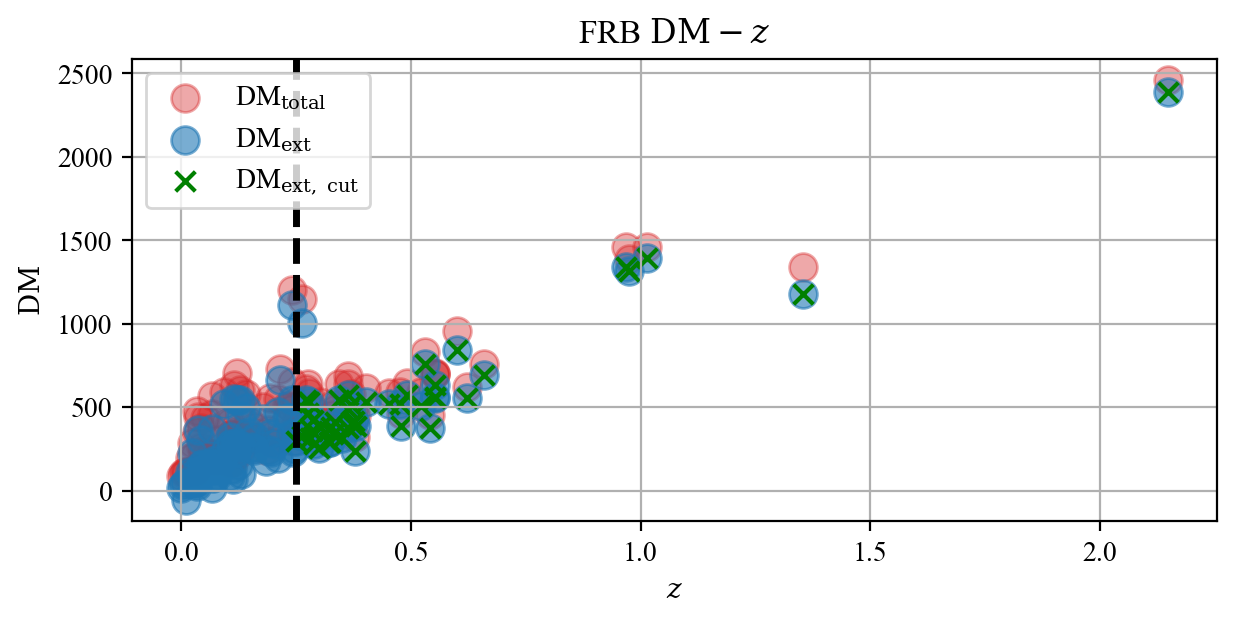

In [8]:
fig = plt.figure(figsize=(7, 3), dpi=200)
ax1 = fig.add_subplot(111)

ax1.scatter(frb_data_all['z'], frb_data_all['DM'], s=100, marker='o', label=r'DM$_{\rm total}$', alpha=0.4, c='tab:red')
ax1.scatter(frb_data_all['z'], frb_data_all['DM_ext(ne2001)'], s=100, marker='o', label=r'DM$_{\rm ext}$', alpha=0.6)
ax1.scatter(frb_data_cut['z'], frb_data_cut['DM_ext(ne2001)'], s=50, marker='x', label=r'DM$_{\rm ext,\ cut}$', c='green')

ax1.axvline(x=z_cut, ls='--', lw=2.5, c='black')
ax1.set_xlabel(r'$z$')
ax1.set_ylabel(r'${\rm DM}$')
ax1.set_title(r'FRB ${\rm DM}-z$')
ax1.grid(True)
ax1.legend(loc='upper left')


if SAVE_FIG:
    plt.savefig("figures/frb_all_cut_DM_z.png", dpi=200, bbox_inches='tight')

plt.show()
plt.close()

# Run MCMC analysis

**Note**:

- For *Gaussian* runs use: `run_mcmc_analysis`.
- For *PDF* runs use: `run_mcmc_analysis_pdf`, and provide the interpolation `data_path`.

**Pade (Approximate) ${\rm DM}$ calculation**

1. Gauss PDF

In [63]:
samples_PD_gauss, flat_samples_PD_gauss = run_mcmc_analysis(frb_data_cut['z'], frb_data_cut['DM_ext(ne2001)'], 200, log_probability_frb_Pade_gauss, N_samples=1500)

100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [01:16<00:00, 19.71it/s]


In [64]:
samples_PD_gauss_lowZ, flat_samples_PD_gauss_lowZ = run_mcmc_analysis(frb_data_cut_lowZ['z'], frb_data_cut_lowZ['DM_ext(ne2001)'], 200, log_probability_frb_Pade_gauss, N_samples=1500)

100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [01:25<00:00, 17.45it/s]


2. Zhuge+2025 PDF

In [65]:
samples_PD_pdf, flat_samples_PD_pdf = run_mcmc_analysis_pdf(frb_data_cut['z'], frb_data_cut['DM_ext(ne2001)'], 200, log_probability_frb_Pade_pdf, DATA_PATH, N_samples=2000)

C:\Users\klera\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [04:20<00:00,  7.67it/s]


In [66]:
samples_PD_pdf_lowZ, flat_samples_PD_pdf_lowZ = run_mcmc_analysis_pdf(frb_data_cut_lowZ['z'], frb_data_cut_lowZ['DM_ext(ne2001)'], 200, log_probability_frb_Pade_pdf, DATA_PATH, N_samples=2000)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [03:57<00:00,  8.42it/s]


3. Zhuge+2025 PDF + host

In [10]:
samples_PD_pdf_host, flat_samples_PD_pdf_host, tau_max =\
run_mcmc_analysis_pdf_host(np.array(frb_data_cut['z']), np.array(frb_data_cut['DM_ext(ne2001)']), 180, log_probability_frb_Pade_pdf_host, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:256: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

In [11]:
samples_PD_pdf_host_lowZ, flat_samples_PD_pdf_host_lowZ, tau_max_lowZ =\
run_mcmc_analysis_pdf_host(np.array(frb_data_cut_lowZ['z']), np.array(frb_data_cut_lowZ['DM_ext(ne2001)']), 180, log_probability_frb_Pade_pdf_host, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:256: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

*Testing extreme cases*

$\sigma_{\rm DM}$ in the code corresponds to the error of the cosmic/diffuse contribution to the DM. The fiducial value of $180$ pc/cm$^3$ corresponds to about 1 intervening halo, while the $50$ one is on the lower side, while the $300$ one would require a few intervening haloes along the way.

What to expect:
- $\sigma_{\rm DM} = 50$ pc/cm$^3$ underestimates the error, and can lead to biases, since a few, especially far away events would drive the posteriors (with effectively minimal errors).
- $\sigma_{\rm DM} = 300$ pc/cm$^3$ overestimates the error, and should make all posteriors wider (downsizing any contribution from high-z events).

In [10]:
samples_PD_pdf_host_s50, flat_samples_PD_pdf_host_s50, tau_max_s50 =\
run_mcmc_analysis_pdf_host(np.array(frb_data_cut['z']), np.array(frb_data_cut['DM_ext(ne2001)']), 50, log_probability_frb_Pade_pdf_host, DATA_PATH, N_samples=15000)

100%|████████████████████████████████████████████████████████████████████████████| 15000/15000 [19:35<00:00, 12.76it/s]


In [11]:
samples_PD_pdf_host_s300, flat_samples_PD_pdf_host_s300, tau_max_s300 =\
run_mcmc_analysis_pdf_host(np.array(frb_data_cut['z']), np.array(frb_data_cut['DM_ext(ne2001)']), 300, log_probability_frb_Pade_pdf_host, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:256: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

4. Zhuge+2025 PDF + host + SD_error

In [12]:
samples_PD_pdf_host_SD, flat_samples_PD_pdf_host_SD, tau_max_SD =\
run_mcmc_analysis_pdf_host_SD(np.array(frb_data_cut['z']), np.array(frb_data_cut['DM_ext(ne2001)']), log_probability_frb_Pade_pdf_host_SD, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:304: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

In [13]:
samples_PD_pdf_host_SD_lowZ, flat_samples_PD_pdf_host_SD_lowZ, tau_max_SD_lowZ =\
run_mcmc_analysis_pdf_host_SD(np.array(frb_data_cut_lowZ['z']), np.array(frb_data_cut_lowZ['DM_ext(ne2001)']), log_probability_frb_Pade_pdf_host_SD, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:304: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

*Testing Gaussian prior on $\sigma_{\rm DM}$*

Impose a prior as $\sigma_{\rm DM} \sim \mathcal{N}(180, 40)$, with limits $0 \leq \sigma_{\rm DM} \leq 900$ pc/cm$^3$.

In [10]:
samples_PD_pdf_host_SD_gauss, flat_samples_PD_pdf_host_SD_gauss, tau_max_SD_gauss =\
run_mcmc_analysis_pdf_host_SD(np.array(frb_data_cut['z']), np.array(frb_data_cut['DM_ext(ne2001)']), log_probability_frb_Pade_pdf_host_SD, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:308: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

In [11]:
samples_PD_pdf_host_SD_gauss_lowZ, flat_samples_PD_pdf_host_SD_gauss_lowZ, tau_max_SD_gauss_lowZ =\
run_mcmc_analysis_pdf_host_SD(np.array(frb_data_cut_lowZ['z']), np.array(frb_data_cut_lowZ['DM_ext(ne2001)']), log_probability_frb_Pade_pdf_host_SD, DATA_PATH, N_samples=15000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:308: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

#### Save posterior data

In [13]:
if SAVE_DATA:
    # np.save('./Obs_study_figures_data/samples_PD_pdf_host.npy', samples_PD_pdf_host)
    # np.save('./Obs_study_figures_data/samples_PD_pdf_host_lowZ.npy', samples_PD_pdf_host_lowZ)
    # np.save('./Obs_study_figures_data/samples_PD_pdf_host_SD.npy', samples_PD_pdf_host_SD)
    # np.save('./Obs_study_figures_data/samples_PD_pdf_host_SD_lowZ.npy', samples_PD_pdf_host_SD_lowZ)

    # np.save('./Obs_study_figures_data/tau_max.npy', tau_max)
    # np.save('./Obs_study_figures_data/tau_max_lowZ.npy', tau_max_lowZ)
    # np.save('./Obs_study_figures_data/tau_max_SD.npy', tau_max_SD)
    # np.save('./Obs_study_figures_data/tau_max_SD_lowZ.npy', tau_max_SD_lowZ)

    # ## Extreme cases
    # np.save('./Obs_study_figures_data/samples_PD_pdf_host_s50.npy', samples_PD_pdf_host_s50)
    # np.save('./Obs_study_figures_data/samples_PD_pdf_host_s300.npy', samples_PD_pdf_host_s300)

    # np.save('./Obs_study_figures_data/tau_max_s50.npy', tau_max_s50)
    # np.save('./Obs_study_figures_data/tau_max_s300.npy', tau_max_s300)

    ## Gaussian prior on SD
    np.save('./Obs_study_figures_data/samples_PD_pdf_host_SD_gauss.npy', samples_PD_pdf_host_SD_gauss)
    np.save('./Obs_study_figures_data/samples_PD_pdf_host_SD_gauss_lowZ.npy', samples_PD_pdf_host_SD_gauss_lowZ)

    np.save('./Obs_study_figures_data/tau_max_SD_gauss.npy', tau_max_SD_gauss)
    np.save('./Obs_study_figures_data/tau_max_SD_gauss_lowZ.npy', tau_max_SD_gauss_lowZ)    

#### Load posterior data

In [14]:
if LOAD_DATA:
    # samples_PD_pdf_host = np.load('./Obs_study_figures_data/samples_PD_pdf_host.npy')
    # samples_PD_pdf_host_lowZ = np.load('./Obs_study_figures_data/samples_PD_pdf_host_lowZ.npy')
    samples_PD_pdf_host_SD = np.load('./Obs_study_figures_data/samples_PD_pdf_host_SD.npy')
    samples_PD_pdf_host_SD_lowZ = np.load('./Obs_study_figures_data/samples_PD_pdf_host_SD_lowZ.npy')

    # tau_max = np.load('./Obs_study_figures_data/tau_max.npy')
    # tau_max_lowZ = np.load('./Obs_study_figures_data/tau_max_lowZ.npy')
    # tau_max_SD = np.load('./Obs_study_figures_data/tau_max_SD.npy')
    # tau_max_SD_lowZ = np.load('./Obs_study_figures_data/tau_max_SD_lowZ.npy')

    ## Extreme cases
    # samples_PD_pdf_host_s50 = np.load('./Obs_study_figures_data/samples_PD_pdf_host_s50.npy')
    # samples_PD_pdf_host_s300 = np.load('./Obs_study_figures_data/samples_PD_pdf_host_s300.npy')
    
    # tau_max_s50 = np.load('./Obs_study_figures_data/tau_max_s50.npy')
    # tau_max_s300 = np.load('./Obs_study_figures_data/tau_max_s300.npy')

Get flat samples

In [15]:
def get_flat_samples(samples, thin=1, burn=200):
    Nparam = samples.shape[2]

    burned_and_thinned = samples[burn::thin, :, :]

    flat_samples = burned_and_thinned.reshape(-1, Nparam)

    return flat_samples

In [20]:
# flat_samples_PD_pdf_host = get_flat_samples(samples_PD_pdf_host)
# flat_samples_PD_pdf_host_lowZ = get_flat_samples(samples_PD_pdf_host_lowZ)
flat_samples_PD_pdf_host_SD = get_flat_samples(samples_PD_pdf_host_SD)
flat_samples_PD_pdf_host_SD_lowZ = get_flat_samples(samples_PD_pdf_host_SD_lowZ)

## Extreme cases
# flat_samples_PD_pdf_host_s50 = get_flat_samples(samples_PD_pdf_host_s50)
# flat_samples_PD_pdf_host_s300 = get_flat_samples(samples_PD_pdf_host_s300)

## Gaussian Priors
flat_samples_PD_pdf_host_SD_gauss = get_flat_samples(samples_PD_pdf_host_SD_gauss)
flat_samples_PD_pdf_host_SD_gauss_lowZ = get_flat_samples(samples_PD_pdf_host_SD_gauss_lowZ)

## Cosmological Constraints

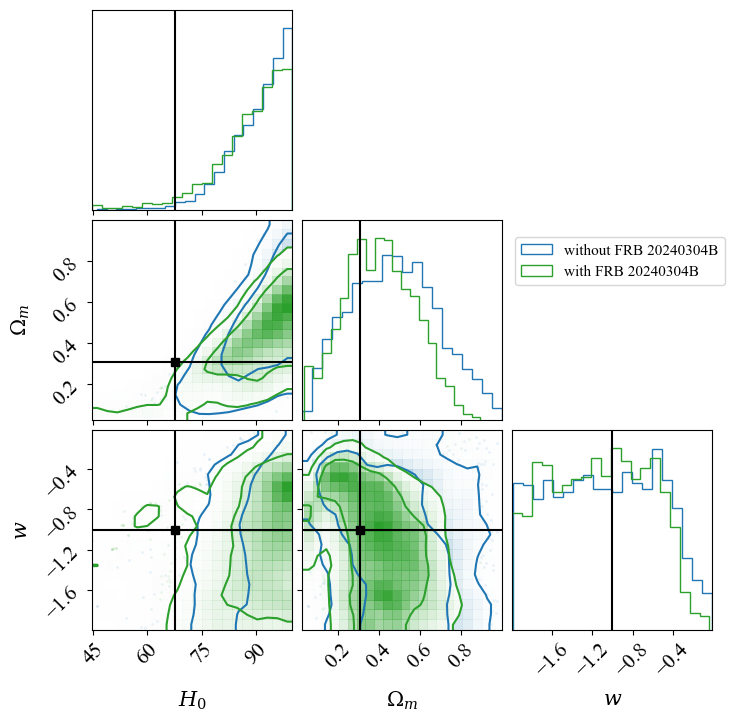

In [67]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]

fig = corner.corner(
    flat_samples_PD_gauss_lowZ, labels=labels, color="tab:blue",\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
corner.corner(
    flat_samples_PD_gauss, fig=fig,\
    levels=(0.68, 0.95), color="tab:green", smooth=True,\
    truths=[HUBBLE, OMEGA_MATTER, W_LAMBDA], truth_color='black'
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

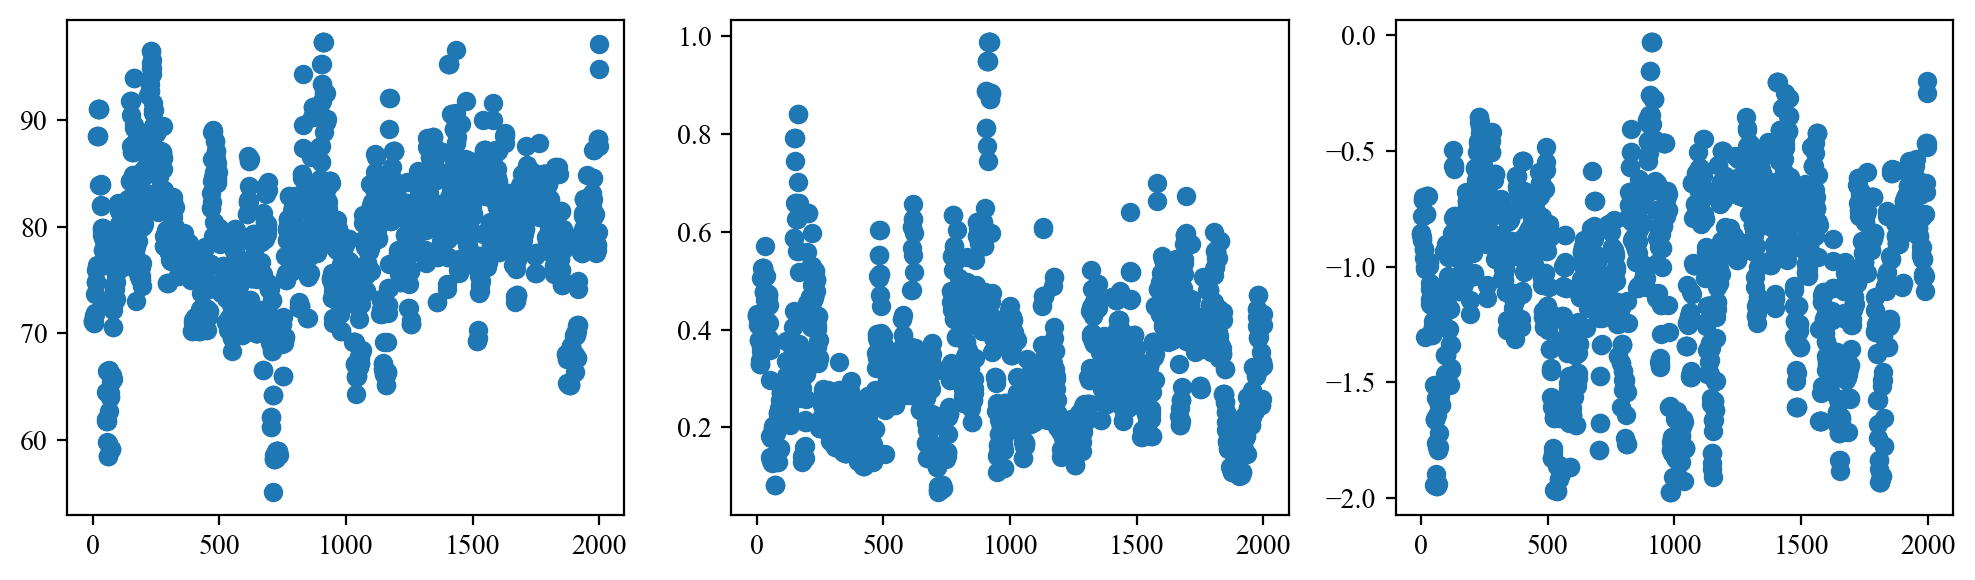

In [70]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]

fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)

for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(flat_samples_PD_gauss_lowZ[:, :, idx], "k", alpha=0.2)
    ax.set_xlim(0, len(flat_samples_PD_gauss_lowZ))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");
axes[0].set_title('Numerical Integration')

plt.show()

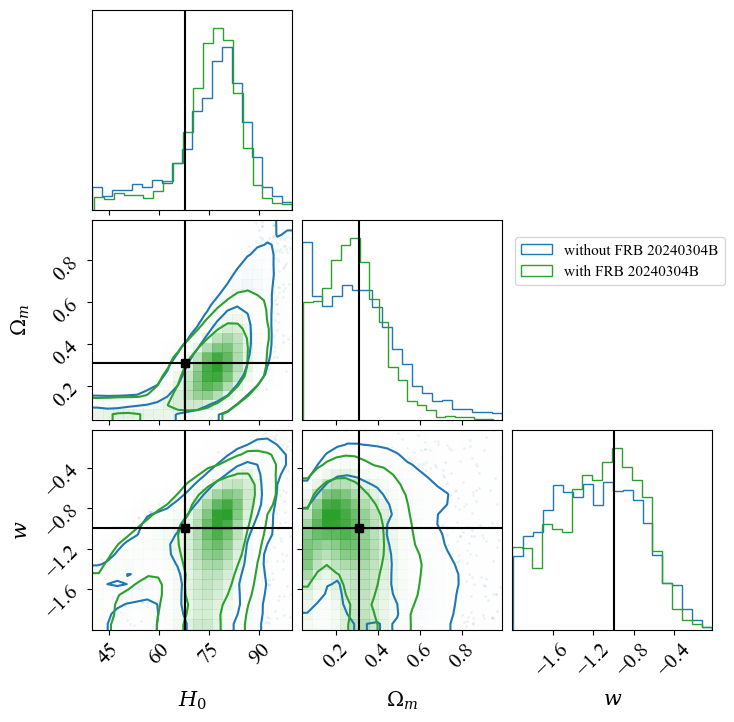

In [69]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]

fig = corner.corner(
    flat_samples_PD_pdf_lowZ, labels=labels, color="tab:blue",\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
corner.corner(
    flat_samples_PD_pdf, fig=fig,\
    levels=(0.68, 0.95), color="tab:green", smooth=True,\
    truths=[HUBBLE, OMEGA_MATTER, W_LAMBDA], truth_color='black'
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

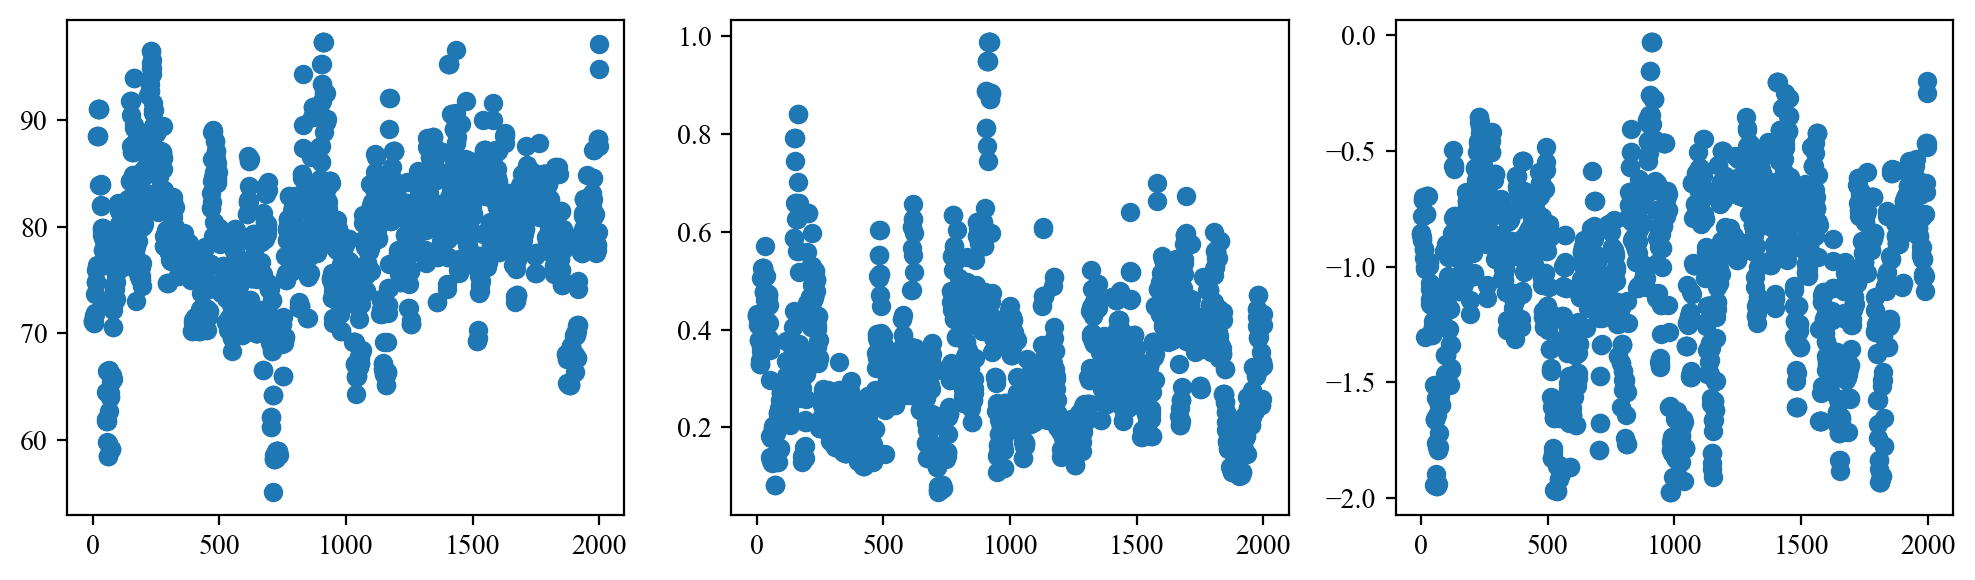

In [70]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]

fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)

for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(flat_samples_PD_pdf_lowZ[:, :, idx], "k", alpha=0.2)
    ax.set_xlim(0, len(flat_samples_PD_pdf_lowZ))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");
axes[0].set_title('Numerical Integration')

plt.show()

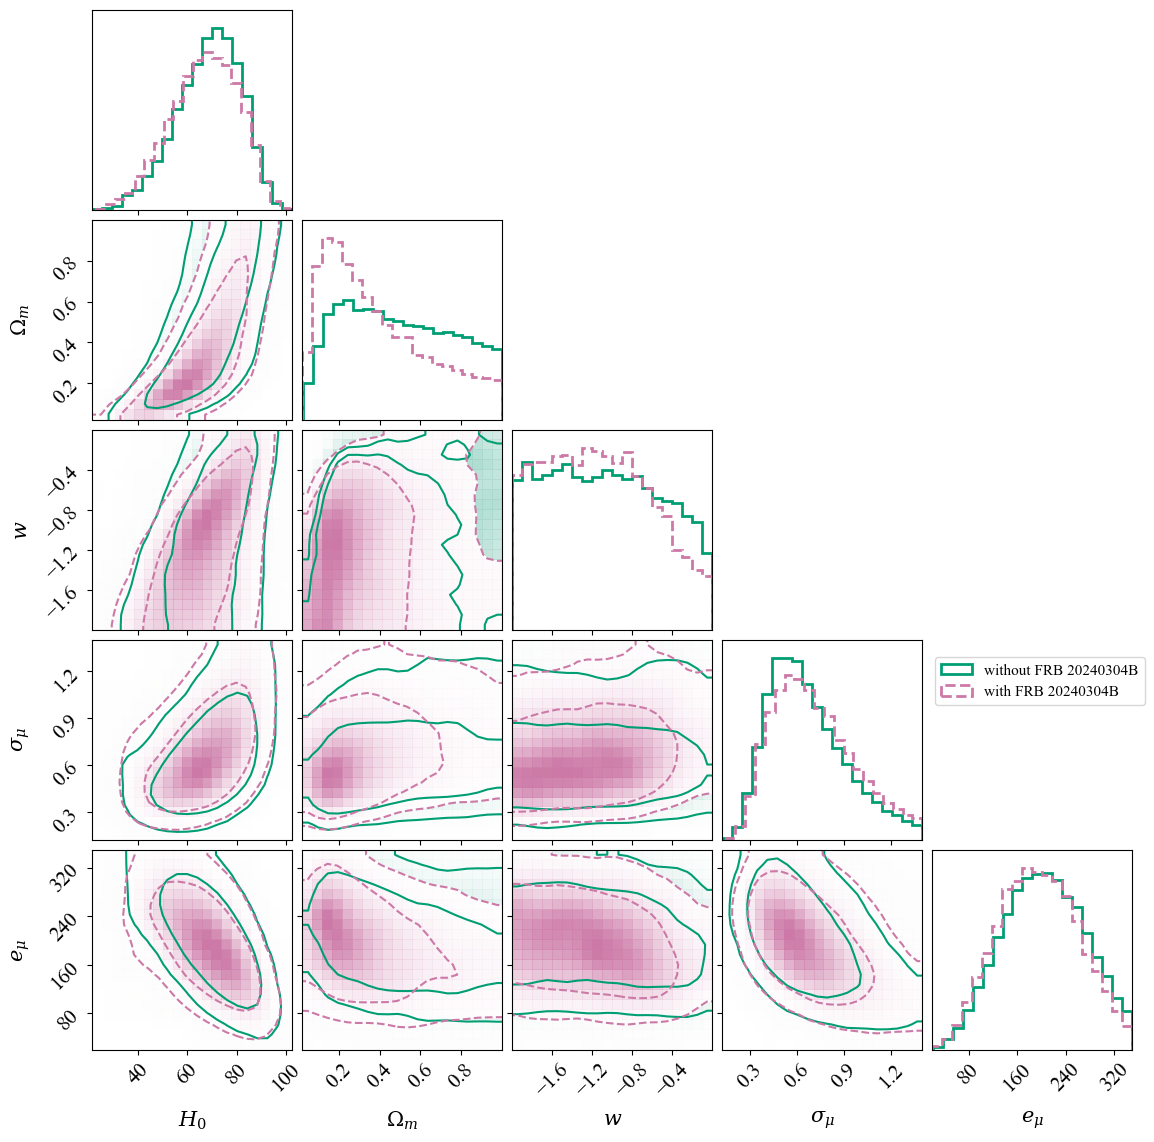

In [15]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$"]

GREEN, PURPLE = "#009E73", "#CC79A7"

fig = corner.corner(
    flat_samples_PD_pdf_host_lowZ, labels=labels, color=GREEN,\
    hist_kwargs=dict(linestyle="-", linewidth=2.0),\
    contour_kwargs=dict(linestyles="-", linewidths=1.5),\
    plot_datapoints=False,\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
fig = corner.corner(
    flat_samples_PD_pdf_host, fig=fig,\
    hist_kwargs=dict(linestyle="--", linewidth=2.0),\
    contour_kwargs=dict(linestyles="--", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=PURPLE, smooth=True
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

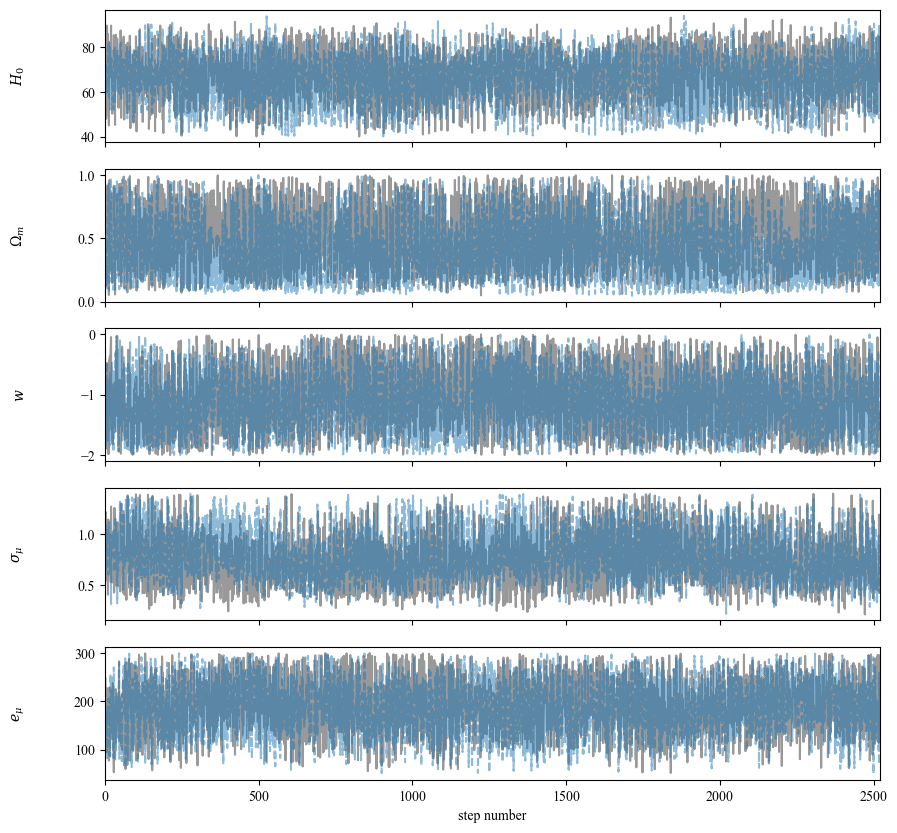

In [12]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$"]

fig, axes = plt.subplots(len(labels), figsize=(10, 10), sharex=True)

for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(flat_samples_PD_pdf_host_lowZ[:, idx], "k", alpha=0.4)
    ax.plot(flat_samples_PD_pdf_host[:, idx], c="tab:blue", ls='--', alpha=0.5)
    ax.set_xlim(0, len(flat_samples_PD_pdf_host_lowZ))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

plt.show()

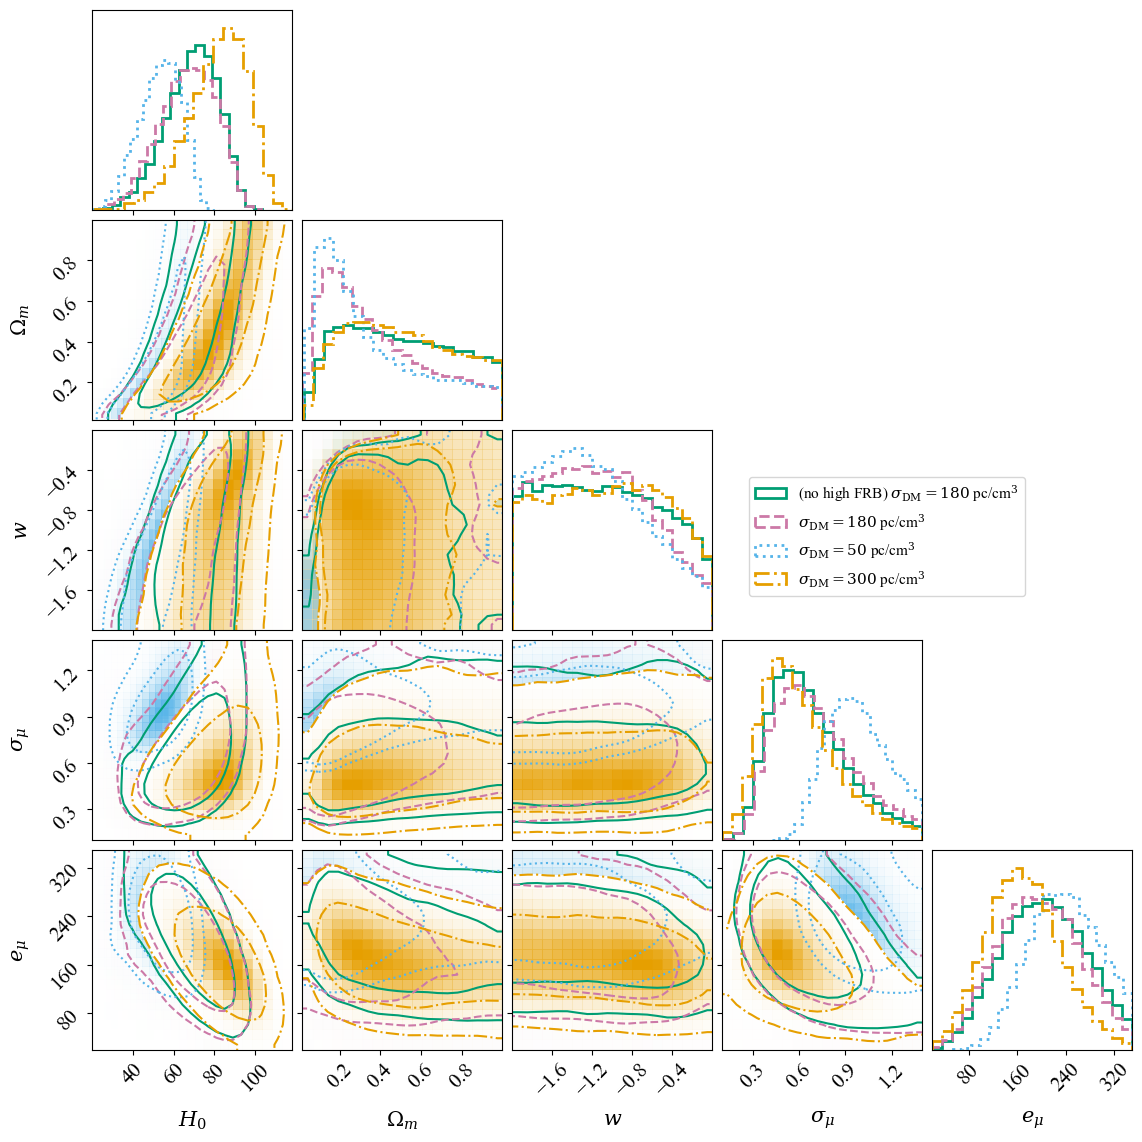

In [34]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$"]

GREEN, ORANGE, BLUE, PURPLE = "#009E73", "#E69F00", "#56B4E9", "#CC79A7"

fig = corner.corner(
    flat_samples_PD_pdf_host_lowZ, labels=labels, color=GREEN,\
    hist_kwargs=dict(linestyle="-", linewidth=2.0),\
    contour_kwargs=dict(linestyles="-", linewidths=1.5),\
    plot_datapoints=False,\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)

corner.corner(
    flat_samples_PD_pdf_host,  fig=fig, color=PURPLE,\
    hist_kwargs=dict(linestyle="--", linewidth=2.0),\
    contour_kwargs=dict(linestyles="--", linewidths=1.5),\
    plot_datapoints=False,\
    smooth=True, levels=(0.68, 0.95)
)

corner.corner(
    flat_samples_PD_pdf_host_s50, fig=fig,\
    hist_kwargs=dict(linestyle=":", linewidth=2.0),\
    contour_kwargs=dict(linestyles=":", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=BLUE, smooth=True
)

corner.corner(
    flat_samples_PD_pdf_host_s300, fig=fig,\
    hist_kwargs=dict(linestyle="-.", linewidth=2.0),\
    contour_kwargs=dict(linestyles="-.", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=ORANGE, smooth=True
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend([r"(no high FRB) $\sigma_{\rm DM} = 180$ pc/cm$^3$", r"$\sigma_{\rm DM} = 180$ pc/cm$^3$", r"$\sigma_{\rm DM} = 50$ pc/cm$^3$", r"$\sigma_{\rm DM} = 300$ pc/cm$^3$"], loc='upper right', bbox_to_anchor=(-0.5, 1.9, 1, 1), fontsize=11)

if SAVE_FIG:
    fig.savefig("./Obs_study_figures_data/corner_4datasets_extreme_SDs.pdf", bbox_inches="tight")
    
plt.show()

----------------------------------------------------------------------

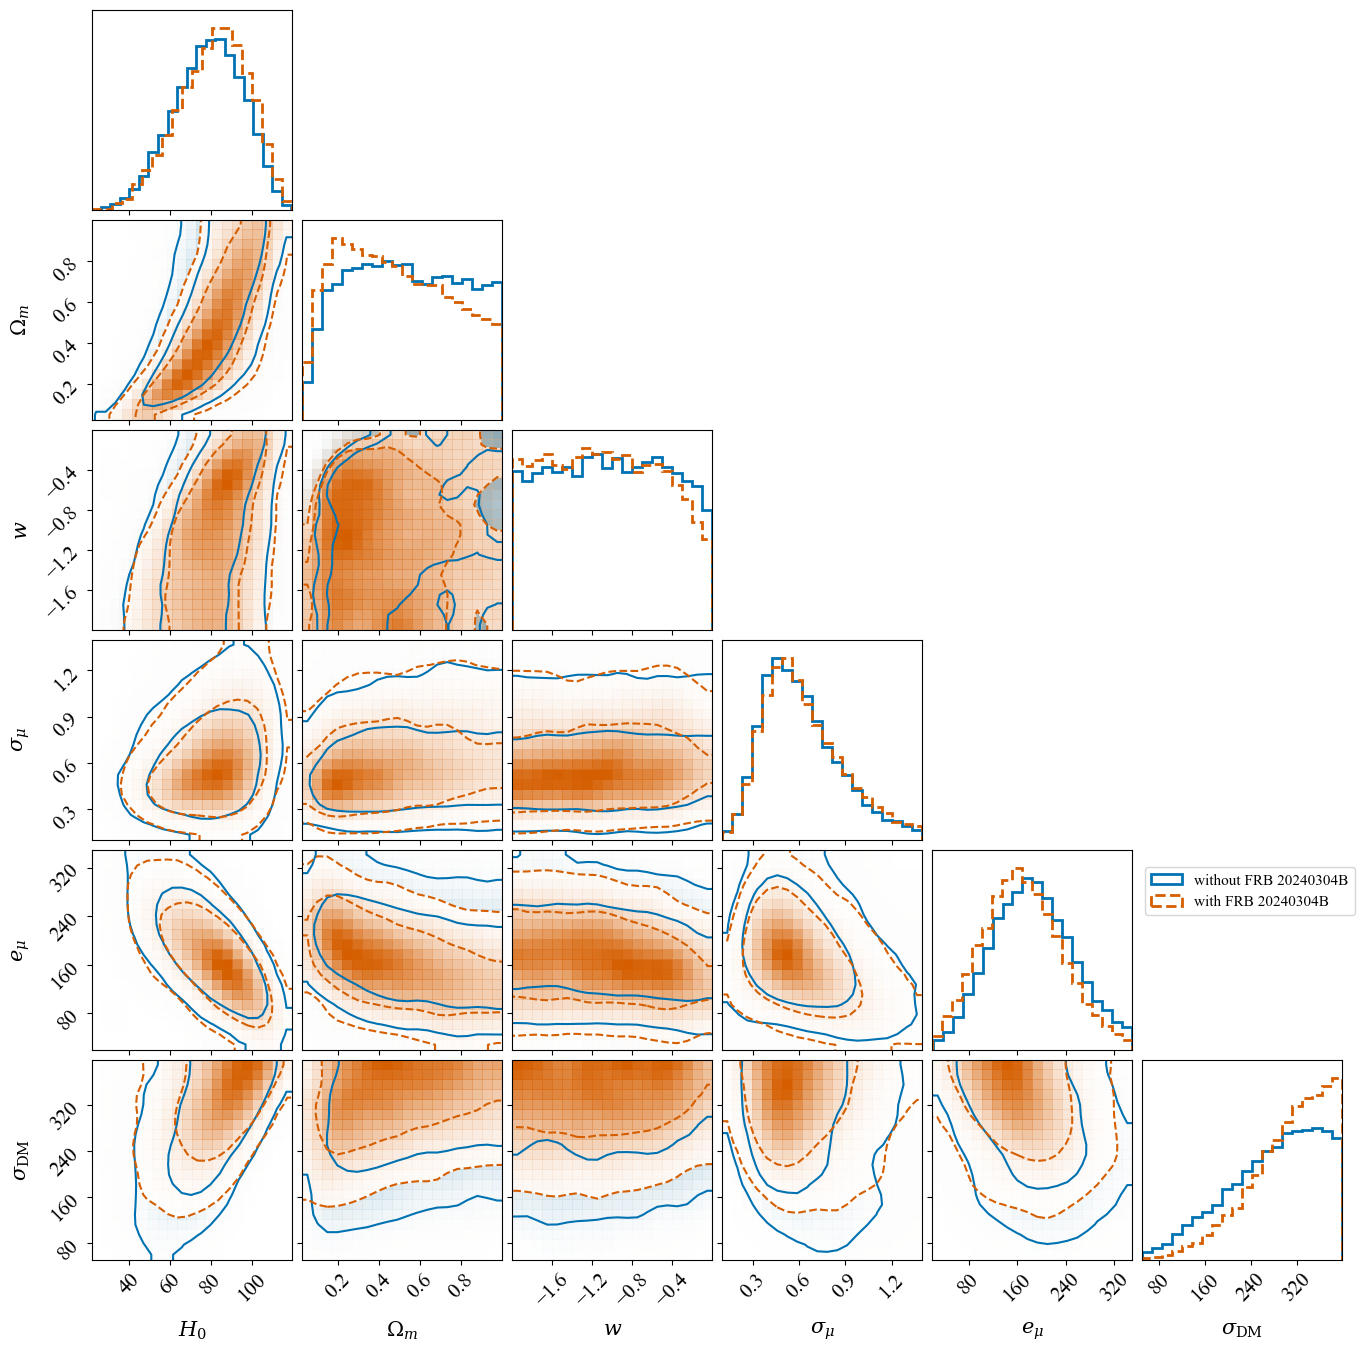

In [16]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$", r"$\sigma_{\rm DM}$"]

BLUE, ORANGE = "#0072B2", "#D55E00"

fig = corner.corner(
    flat_samples_PD_pdf_host_SD_lowZ, labels=labels, color=BLUE,\
    hist_kwargs=dict(linestyle="-", linewidth=2.0),\
    contour_kwargs=dict(linestyles="-", linewidths=1.5),\
    plot_datapoints=False,\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
fig = corner.corner(
    flat_samples_PD_pdf_host_SD, fig=fig,\
    hist_kwargs=dict(linestyle="--", linewidth=2.0),\
    contour_kwargs=dict(linestyles="--", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=ORANGE, smooth=True
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

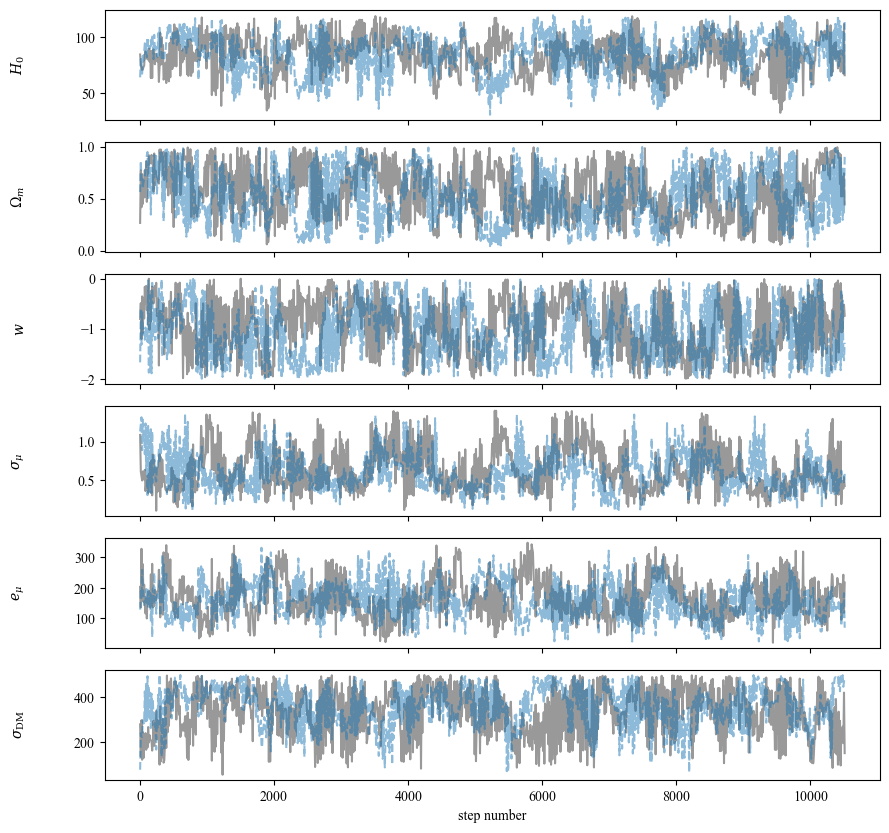

In [12]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$", r"$\sigma_{\rm DM}$"]

fig, axes = plt.subplots(len(labels), figsize=(10, 10), sharex=True)

for idx, name in enumerate(labels):
    ax = axes[idx]
    step_size = 10
    steps = np.arange(0, len(flat_samples_PD_pdf_host_SD_lowZ), step_size)
    ax.plot(steps, flat_samples_PD_pdf_host_SD_lowZ[:, idx][::step_size], "k", alpha=0.4)
    ax.plot(steps, flat_samples_PD_pdf_host_SD[:, idx][::step_size], c="tab:blue", ls='--', alpha=0.5)
    # ax.set_xlim(0, len(flat_samples_PD_pdf_host_SD_lowZ))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

plt.show()

**Combined plot**

In [17]:
from matplotlib.lines import Line2D

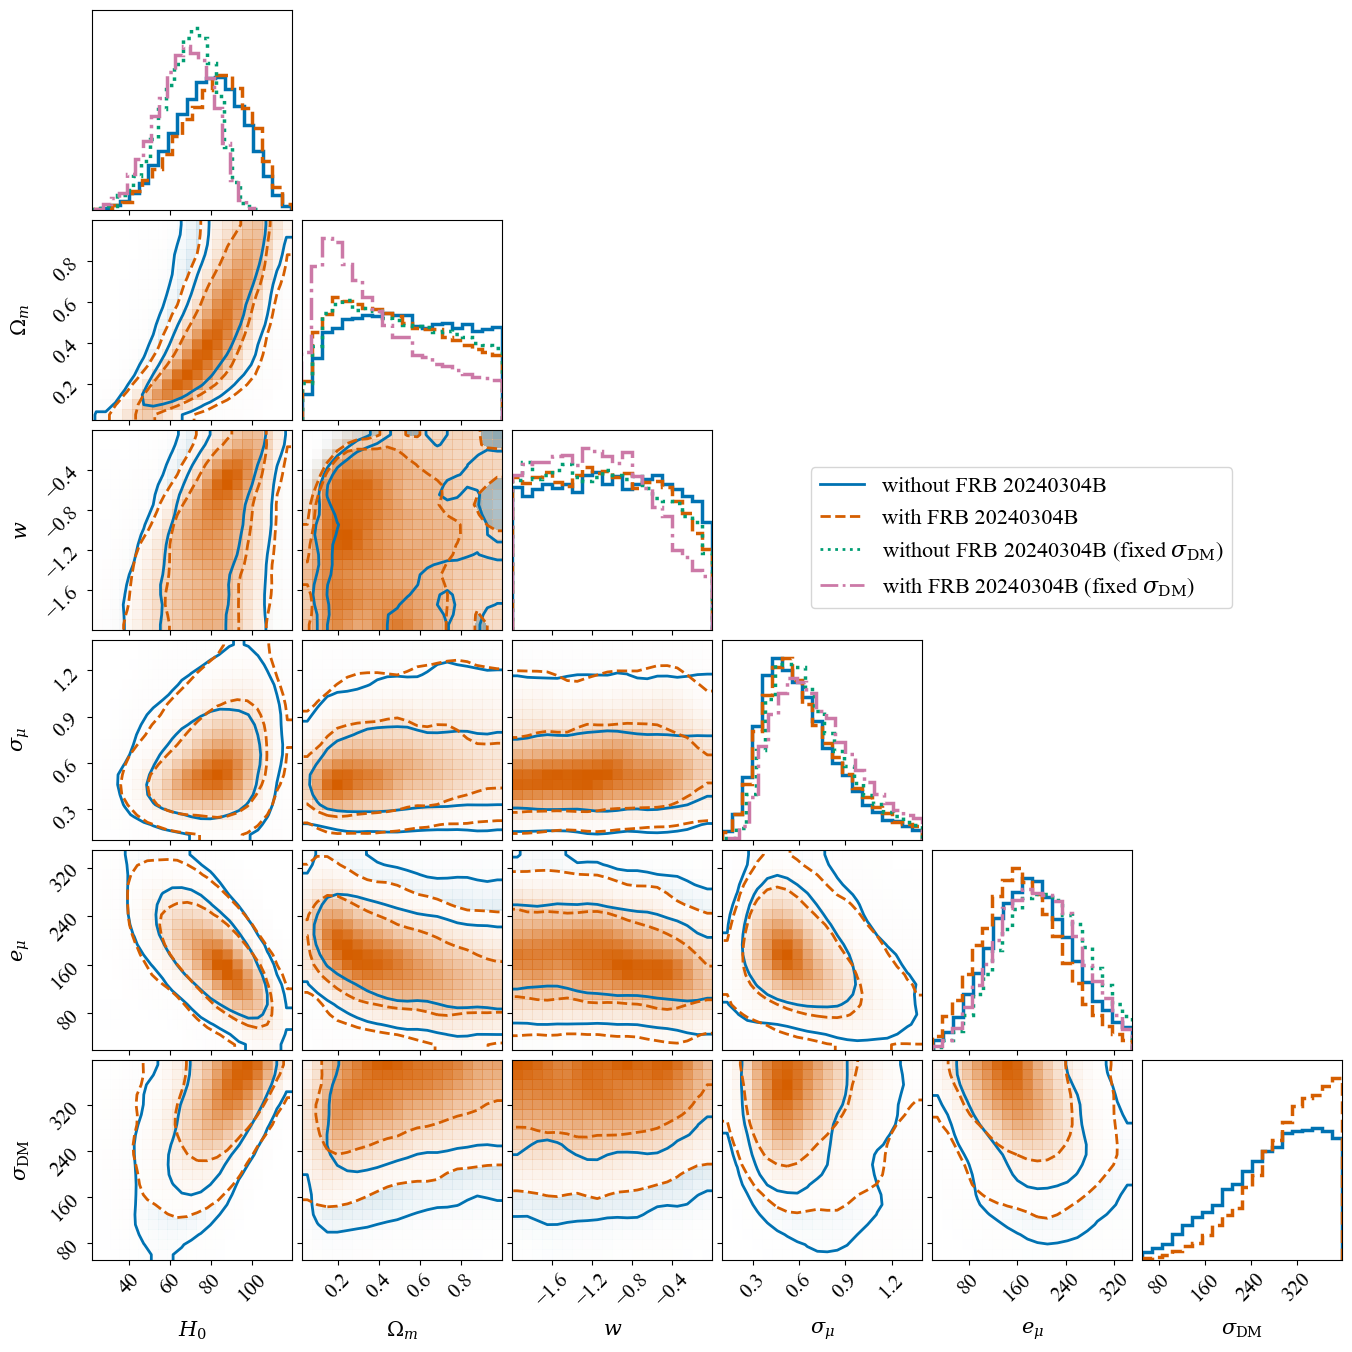

In [18]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$", r"$\sigma_{\rm DM}$"]

BLUE, ORANGE = "#0072B2", "#D55E00"
GREEN, PURPLE = "#009E73", "#CC79A7"

common = dict(
    smooth=True,
    levels=(0.68, 0.95),
    plot_datapoints=False,
    plot_density=True,
    fill_contours=False,
    show_titles=False,
)

Nbins=20

fig = corner.corner(
    flat_samples_PD_pdf_host_SD_lowZ, labels=labels, color=BLUE,\
    hist_kwargs=dict(linestyle="-", linewidth=2.5, density=True),\
    contour_kwargs=dict(linestyles="-", linewidths=2.0),\
    label_kwargs={"fontsize": 15},\
    **common
)

fig = corner.corner(
    flat_samples_PD_pdf_host_SD, fig=fig,\
    hist_kwargs=dict(linestyle="--", linewidth=2.5, density=True),\
    contour_kwargs=dict(linestyles="--", linewidths=2.0),\
    color=ORANGE,\
    **common
);

K = flat_samples_PD_pdf_host_SD_lowZ.shape[1]
axes = np.array(fig.axes).reshape((K, K)) 

extra = [
    (flat_samples_PD_pdf_host_lowZ, GREEN,  ":",  "Dataset 3"),
    (flat_samples_PD_pdf_host, PURPLE, "-.", "Dataset 4"),
]

all_samples = [flat_samples_PD_pdf_host_SD_lowZ, flat_samples_PD_pdf_host_SD,\
               flat_samples_PD_pdf_host_lowZ, flat_samples_PD_pdf_host]


for samples, color, ls, _ in extra:
    for i in range(K-1):
        ymax = max(
        np.histogram(s[:, i], bins=Nbins, density=True)[0].max()
        for s in all_samples)

        ax = axes[i, i]
        ax.set_ylim(0, 1.1 * ymax)
        
        n, _, _ = ax.hist(
            samples[:, i],
            bins = Nbins,
            histtype="step",
            density=True,
            color=color,
            linestyle=ls,
            linewidth=2.5,
        )
        

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

handles = [
    Line2D([], [], color=BLUE,   ls="-",  lw=2, label="without FRB 20240304B"),
    Line2D([], [], color=ORANGE, ls="--", lw=2, label="with FRB 20240304B"),
    Line2D([], [], color=GREEN,  ls=":",  lw=2, label=r"without FRB 20240304B (fixed $\sigma_{\rm DM}$)"),
    Line2D([], [], color=PURPLE, ls="-.", lw=2, label=r"with FRB 20240304B (fixed $\sigma_{\rm DM}$)"),
]
fig.legend(handles=handles, loc="upper right", frameon=True, fontsize=16, bbox_to_anchor=(-0.1, -0.35, 1, 1))    

if SAVE_FIG:    
    fig.savefig("./Obs_study_figures_data/corner_4datasets.pdf", bbox_inches="tight")
    
plt.show()

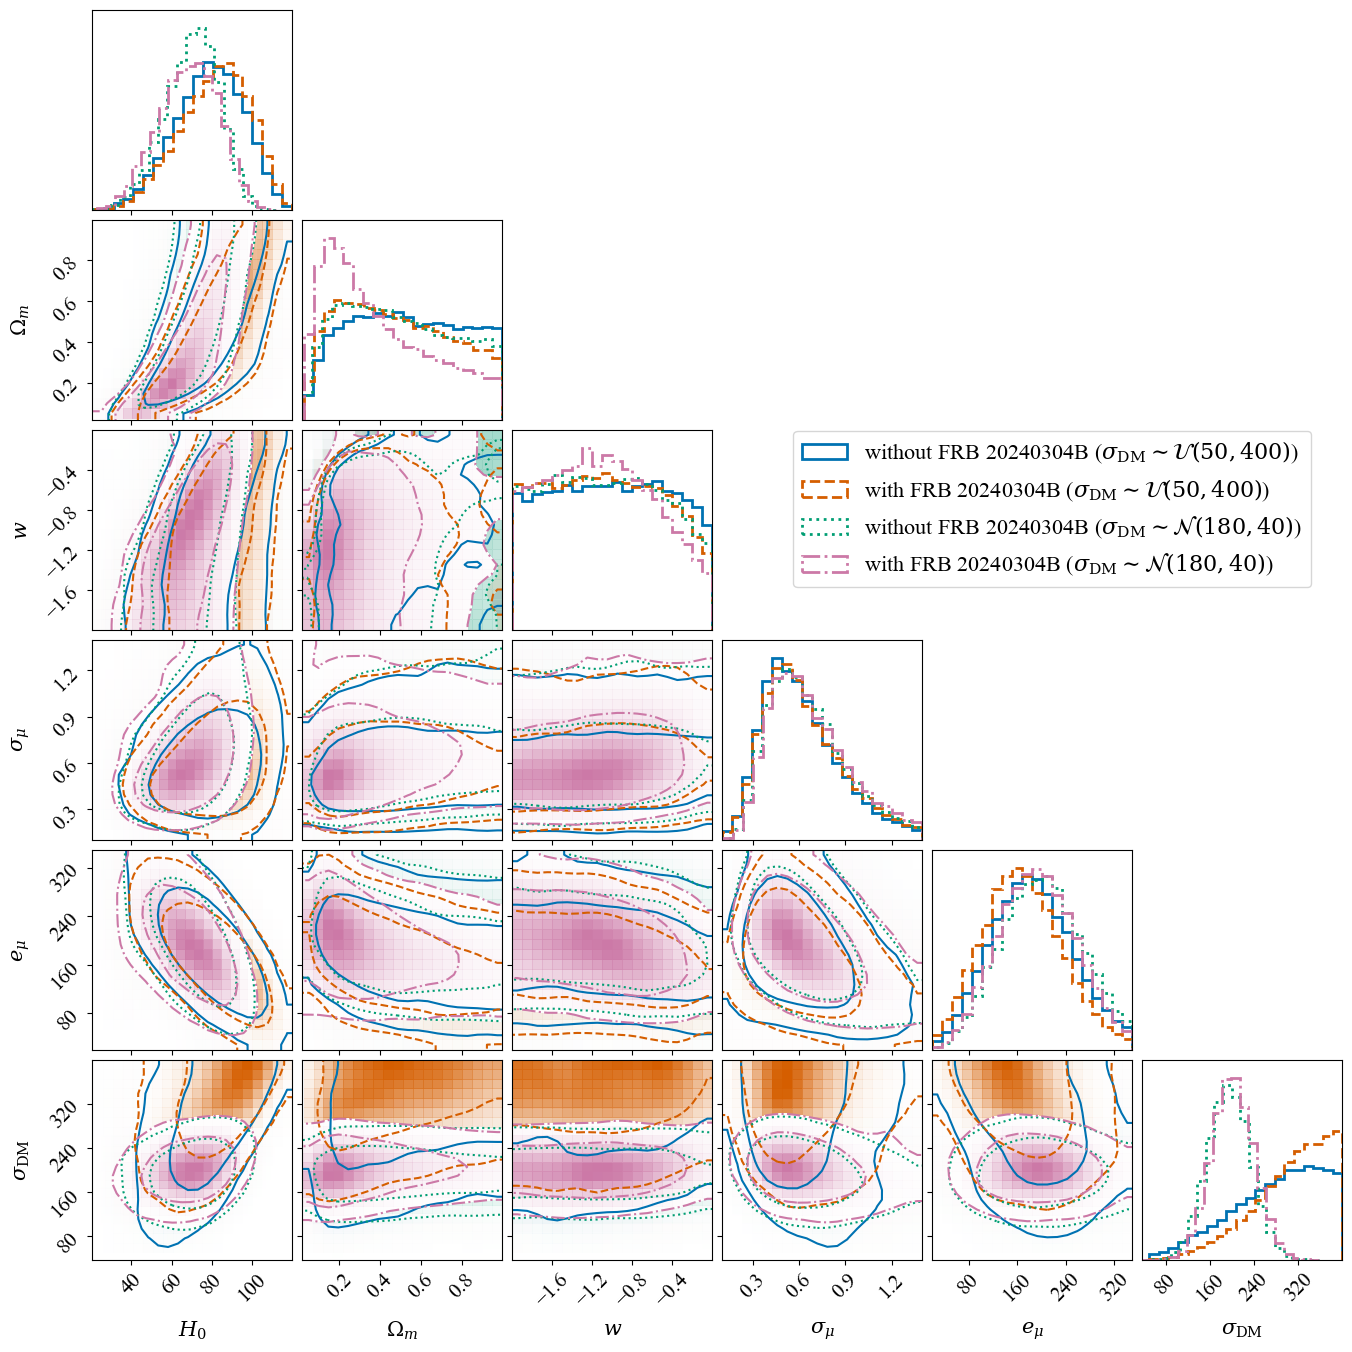

In [32]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$", r"$\sigma_{\rm DM}$"]

BLUE, ORANGE = "#0072B2", "#D55E00"
GREEN, PURPLE = "#009E73", "#CC79A7"

fig = corner.corner(
    flat_samples_PD_pdf_host_SD_lowZ, labels=labels, color=BLUE,\
    hist_kwargs=dict(linestyle="-", linewidth=2.0),\
    contour_kwargs=dict(linestyles="-", linewidths=1.5),\
    plot_datapoints=False,\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
fig = corner.corner(
    flat_samples_PD_pdf_host_SD, fig=fig,\
    hist_kwargs=dict(linestyle="--", linewidth=2.0),\
    contour_kwargs=dict(linestyles="--", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=ORANGE, smooth=True
)

fig = corner.corner(
    flat_samples_PD_pdf_host_SD_gauss_lowZ, fig=fig,\
    hist_kwargs=dict(linestyle=":", linewidth=2.0),\
    contour_kwargs=dict(linestyles=":", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=GREEN, smooth=True
)

fig = corner.corner(
    flat_samples_PD_pdf_host_SD_gauss, fig=fig,\
    hist_kwargs=dict(linestyle="-.", linewidth=2.0),\
    contour_kwargs=dict(linestyles="-.", linewidths=1.5),\
    plot_datapoints=False,\
    levels=(0.68, 0.95), color=PURPLE, smooth=True
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend([r"without FRB 20240304B ($\sigma_{\rm DM} \sim \mathcal{U}(50, 400)$)",\
            r"with FRB 20240304B ($\sigma_{\rm DM} \sim \mathcal{U}(50, 400)$)",\
           r"without FRB 20240304B ($\sigma_{\rm DM} \sim \mathcal{N}(180, 40)$)",\
           r"with FRB 20240304B ($\sigma_{\rm DM} \sim \mathcal{N}(180, 40)$)"],\
           loc='upper right', bbox_to_anchor=(-0.1, 3.2, 1, 1), fontsize=16)

if SAVE_FIG:    
    fig.savefig("./Obs_study_figures_data/corner_SD_Gaussian_Uniform_prior.pdf", bbox_inches="tight")
    
plt.show()

------------------------------------------------------------

## Quantitative analysis of differences

In [5]:
from scipy.stats import wasserstein_distance

In [6]:
def per_param_report(full, loo, names):
    mu_f, mu_l = full.mean(0), loo.mean(0)
    sd_f, sd_l = full.std(0), loo.std(0)
    for k, name in enumerate(names):
        shift = (mu_f[k] - mu_l[k]) / sd_f[k]
        width = sd_l[k] / sd_f[k] - 1
        w1 = wasserstein_distance(full[:, k], loo[:, k]) / sd_f[k]
        print(fr"{name:>8s}  shift={shift:+.3f}σ  width={width:+.3f}  W1={w1:.3f}σ")

In [17]:
def block_bootstrap(chain, block_len, rng):
    nsteps, nwalkers, ndim = chain.shape
    nblocks = nsteps // block_len
    blocks = chain[:nblocks * block_len].reshape(nblocks, block_len, nwalkers, ndim)
    idx = rng.integers(0, nblocks, size=nblocks)
    return blocks[idx].reshape(-1, ndim)

In [14]:
per_param_report(flat_samples_PD_pdf_host, flat_samples_PD_pdf_host_lowZ, ['H0', 'Om', 'w', 'S_mu', 'e_mu'])

      H0  shift=-0.145σ  width=-0.056  W1=0.145σ
      Om  shift=-0.431σ  width=+0.041  W1=0.431σ
       w  shift=-0.129σ  width=+0.069  W1=0.129σ
    S_mu  shift=+0.159σ  width=-0.042  W1=0.159σ
    e_mu  shift=-0.133σ  width=+0.020  W1=0.133σ


In [15]:
per_param_report(flat_samples_PD_pdf_host_SD, flat_samples_PD_pdf_host_SD_lowZ, ['H0', 'Om', 'w', 'S_mu', 'e_mu', 'SD'])

      H0  shift=+0.157σ  width=-0.018  W1=0.157σ
      Om  shift=-0.182σ  width=+0.009  W1=0.182σ
       w  shift=-0.081σ  width=+0.025  W1=0.081σ
    S_mu  shift=+0.063σ  width=-0.027  W1=0.063σ
    e_mu  shift=-0.245σ  width=+0.030  W1=0.245σ
      SD  shift=+0.395σ  width=+0.191  W1=0.395σ


Bootsrapping to get an estimate of the MCMC errors

In [22]:
samples_PD_pdf_host.shape, flat_samples_PD_pdf_host.shape

((15000, 20, 5), (296000, 5))

In [19]:
samples_all_list = [samples_PD_pdf_host, samples_PD_pdf_host_lowZ,\
               samples_PD_pdf_host_SD, samples_PD_pdf_host_SD_lowZ]

samples_names = ['With FRB 20240304B, fixed SD', 'Without FRB 20240304B, fixed SD',\
                 'With FRB 20240304B, varying SD', 'Without FRB 20240304B, varying SD']

tau_max_all = [tau_max, tau_max_lowZ, tau_max_SD, tau_max_SD_lowZ]

Nburn = 200

# Burn-in removed manually, NOT thinned, shape preserved
for idx, samples_all in enumerate(samples_all_list):
    print(f"We are analysing samples from the run: {samples_names[idx]}.")
    chain = samples_all[Nburn:]            # (nsteps, nwalkers, ndim)
    nsteps, nwalkers, ndim = chain.shape
    
    # Block length: about 8 autocorrelation times
    block_len = int(np.ceil(9 * tau_max_all[idx]))
    nblocks = nsteps // block_len
    print(f"block_len={block_len}, nblocks={nblocks}")
    if nblocks < 9:
        print("Warning: few blocks, the bootstrap will be unstable. Run a longer chain.")
    
    # Reference posterior: the full burned-in chain, flattened
    ref_flat = chain.reshape(-1, ndim)
    mu_ref = ref_flat.mean(0)
    sd_ref = ref_flat.std(0)
    
    rng = np.random.default_rng(42)
    noise_shift, noise_w1 = [], []
    for _ in tqdm(range(500)):
        b = block_bootstrap(chain, block_len, rng)
        noise_shift.append(np.abs(b.mean(0) - mu_ref) / sd_ref)
        noise_w1.append([wasserstein_distance(b[:, k], ref_flat[:, k]) / sd_ref[k]
                         for k in range(ndim)])
    
    noise_shift = np.array(noise_shift)
    noise_w1 = np.array(noise_w1)
    
    print("95% noise floor, shift [σ]:", np.round(np.percentile(noise_shift, 95, axis=0), 3))
    print("95% noise floor, W1 [σ]:  ", np.round(np.percentile(noise_w1, 95, axis=0), 3), "\n")

We are analysing samples from the run: With FRB 20240304B, fixed SD.
block_len=1461, nblocks=10


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [07:00<00:00,  1.19it/s]


95% noise floor, shift [σ]: [0.047 0.041 0.037 0.054 0.023]
95% noise floor, W1 [σ]:   [0.047 0.041 0.037 0.054 0.023] 

We are analysing samples from the run: Without FRB 20240304B, fixed SD.
block_len=1242, nblocks=11


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [06:30<00:00,  1.28it/s]


95% noise floor, shift [σ]: [0.033 0.042 0.042 0.027 0.034]
95% noise floor, W1 [σ]:   [0.033 0.044 0.043 0.028 0.035] 

We are analysing samples from the run: With FRB 20240304B, varying SD.
block_len=1737, nblocks=8


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [07:52<00:00,  1.06it/s]


95% noise floor, shift [σ]: [0.041 0.046 0.036 0.062 0.028 0.025]
95% noise floor, W1 [σ]:   [0.042 0.046 0.036 0.062 0.03  0.025] 

We are analysing samples from the run: Without FRB 20240304B, varying SD.
block_len=1554, nblocks=9


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [07:47<00:00,  1.07it/s]

95% noise floor, shift [σ]: [0.057 0.053 0.056 0.033 0.049 0.038]
95% noise floor, W1 [σ]:   [0.058 0.053 0.056 0.033 0.049 0.038] 



In [25]:
def prepare_chain(samples_all, Nburn, tau_max, factor=9):
    chain = samples_all[Nburn:]                      # (nsteps, nwalkers, ndim)
    block_len = int(np.ceil(factor * tau_max))
    nblocks = chain.shape[0] // block_len
    print(f"block_len={block_len}, nblocks={nblocks}")
    if nblocks < 9:
        print("Warning: few blocks, the bootstrap will be unstable.")
    return chain, block_len

In [28]:
def compare_chains(full_chain1, flat_chain1, tau_max1,\
                   full_chain2, flat_chain2, tau_max2,\
                   names, NBURN=200, NBOOT=500):

    chain1, bl1 = prepare_chain(full_chain1, NBURN, tau_max1)
    chain2, bl2 = prepare_chain(full_chain2, NBURN, tau_max2)

    ndim = flat_chain1.shape[1]

    # Reference statistics: chain 1 (full) sets the units
    mu1, sd1 = flat_chain1.mean(0), flat_chain1.std(0)
    mu2, sd2 = flat_chain2.mean(0), flat_chain2.std(0)


    # Paired bootstrap: each chain resampled independently, replicates paired by index
    rng = np.random.default_rng(12345)
    mean_noise = np.empty((NBOOT, ndim))
    width_noise = np.empty((NBOOT, ndim))
    for i in tqdm(range(NBOOT)):
        b1 = block_bootstrap(chain1, bl1, rng)
        b2 = block_bootstrap(chain2, bl2, rng)
        # Noise-only differences, centered on zero (null of "no effect")
        mean_noise[i] = ((b1.mean(0) - mu1) - (b2.mean(0) - mu2)) / sd1
        width_noise[i] = (b2.std(0) / b1.std(0)) / (sd2 / sd1) - 1
    
    # Observed effects
    shift_obs = (mu1 - mu2) / sd1
    width_obs = sd2 / sd1 - 1
    
    # 95% thresholds for |effect| under the null of pure MC noise
    shift_thr = np.percentile(np.abs(mean_noise), 95, axis=0)
    width_thr = np.percentile(np.abs(width_noise), 95, axis=0)
    
    print(f"{'param':>6s} {'shift[σ]':>9s} {'thr':>6s} {'signif':>7s} | {'width':>7s} {'thr':>6s} {'signif':>7s}")
    for k, name in enumerate(names):
        s_sig = abs(shift_obs[k]) > shift_thr[k]
        w_sig = abs(width_obs[k]) > width_thr[k]
        print(f"{name:>6s} {shift_obs[k]:+9.3f} {shift_thr[k]:6.3f} {str(s_sig):>7s} | "
              f"{width_obs[k]:+7.3f} {width_thr[k]:6.3f} {str(w_sig):>7s}")

In [29]:
compare_chains(samples_PD_pdf_host, flat_samples_PD_pdf_host, tau_max,\
               samples_PD_pdf_host_lowZ, flat_samples_PD_pdf_host_lowZ, tau_max_lowZ,\
               ['H0', 'Om', 'w', 'S_mu', 'e_mu'])

block_len=1461, nblocks=10
block_len=1242, nblocks=11


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [00:28<00:00, 17.35it/s]

 param  shift[σ]    thr  signif |   width    thr  signif
    H0    -0.145  0.057    True |  -0.056  0.039    True
    Om    -0.431  0.056    True |  +0.041  0.022    True
     w    -0.129  0.067    True |  +0.069  0.016    True
  S_mu    +0.159  0.056    True |  -0.042  0.027    True
  e_mu    -0.133  0.043    True |  +0.020  0.021   False


In [30]:
compare_chains(samples_PD_pdf_host_SD, flat_samples_PD_pdf_host_SD, tau_max_SD,\
               samples_PD_pdf_host_SD_lowZ, flat_samples_PD_pdf_host_SD_lowZ, tau_max_SD_lowZ,\
               ['H0', 'Om', 'w', 'S_mu', 'e_mu', 'SD'])

block_len=1737, nblocks=8
block_len=1554, nblocks=9


100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [00:31<00:00, 15.90it/s]

 param  shift[σ]    thr  signif |   width    thr  signif
    H0    +0.157  0.074    True |  -0.018  0.020   False
    Om    -0.182  0.073    True |  +0.009  0.017   False
     w    -0.081  0.073    True |  +0.025  0.013    True
  S_mu    +0.063  0.072   False |  -0.027  0.027   False
  e_mu    -0.245  0.063    True |  +0.030  0.026    True
    SD    +0.395  0.051    True |  +0.191  0.025    True
